# EDA der aufbereiteten Daten

**House Demand Forecasting**

Dieses Notebook untersucht die vorbereiteten Merkmale, ihre Verteilungen und ihre Zusammenhänge mit DOM und Pending Listings. Die gespeicherten Trainingsdaten werden übernommen. Es werden weder erneut Daten standardisiert noch Prognosemodelle trainiert.



## 1. Daten laden und Analysebasis prüfen

Die vorbereiteten Trainingsdaten werden eingelesen. Die Hauptanalyse verwendet 56 Beobachtungen für einen Prognosehorizont von einem Monat. Ergänzend werden längere Horizonte betrachtet. Die Prüfung stellt sicher, dass ursprüngliche und standardisierte Tabellen dieselben Beobachtungen enthalten. Kalendermerkmale und Zielwerte bleiben in ihrer ursprünglichen Form.


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap

project_dir = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
data_dir = project_dir / "ergebnisse" / "data_preparation_A"
output_dir = project_dir / "ergebnisse" / "eda"
if not data_dir.is_dir():
    raise FileNotFoundError("Bitte zuerst Block 7 der Data Preparation ausführen: ergebnisse/data_preparation fehlt.")
output_dir.mkdir(parents=True, exist_ok=True)

raw_tables, scaled_tables = {}, {}
for horizon in range(1, 13):
    raw_path = data_dir / f"eda_train_h{horizon:02d}_unscaled.csv"
    scaled_path = data_dir / f"eda_train_h{horizon:02d}_scaled.csv"
    if not scaled_path.is_file():
        scaled_path = data_dir / f"eda_train_h{horizon:02d}_standardized.csv"
    raw_tables[horizon] = pd.read_csv(raw_path)
    scaled_tables[horizon] = pd.read_csv(scaled_path)
    for frame in [raw_tables[horizon], scaled_tables[horizon]]:
        for column in ["origin_month", "target_month", "target_available_month_assumed"]:
            frame[column] = pd.to_datetime(frame[column])

raw_data = raw_tables[1]
scaled_data = scaled_tables[1]
lag_columns = [column for column in raw_data if "_lag_" in column]
feature_columns = lag_columns + ["month_sin", "month_cos"]
assert len(lag_columns) == 8
for horizon in range(1, 13):
    raw_frame, scaled_frame = raw_tables[horizon], scaled_tables[horizon]
    assert raw_frame.origin_month.equals(scaled_frame.origin_month)
    assert raw_frame.target_month.equals(scaled_frame.target_month)
    assert raw_frame.target_available_month_assumed.max() <= pd.Timestamp("2023-07-01")
    assert np.isfinite(scaled_frame[feature_columns + ["target_dom", "target_pending"]]).all().all()
    np.testing.assert_allclose(raw_frame[["month_sin", "month_cos", "target_dom", "target_pending"]], scaled_frame[["month_sin", "month_cos", "target_dom", "target_pending"]])
    np.testing.assert_allclose(scaled_frame[lag_columns].mean(), 0, atol=1e-10)
    np.testing.assert_allclose(scaled_frame[lag_columns].std(ddof=0), 1, atol=1e-10)
assert [len(raw_tables[horizon]) for horizon in [1, 3, 6, 12]] == [56, 54, 51, 45]
plot_blue, plot_light_blue, plot_red = "#173E65", "#4E91BE", "#C73549"
plot_cmap = LinearSegmentedColormap.from_list("project_colors", [plot_blue, plot_light_blue, "white", "#D87885", "#B52439"])
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11})

def show_figure(figure, file_name):
    figure.savefig(output_dir / file_name, dpi=180, bbox_inches="tight", facecolor="white")
    plt.show()

## 2. Verteilungen und auffällige Werte

Die Histogramme zeigen, wie häufig die standardisierten Werte der acht Lag-Features vorkommen. Die gestrichelte blaue Linie markiert den Mittelwert null, die rote Linie den Median. Zusätzlich werden Schiefe und die Anzahl auffälliger Werte außerhalb der üblichen Boxplot-Grenzen berechnet und als CSV gespeichert. Solche Werte werden geprüft, aber nicht automatisch entfernt. Die Boxplots aus Data Preparation werden hier nicht wiederholt.


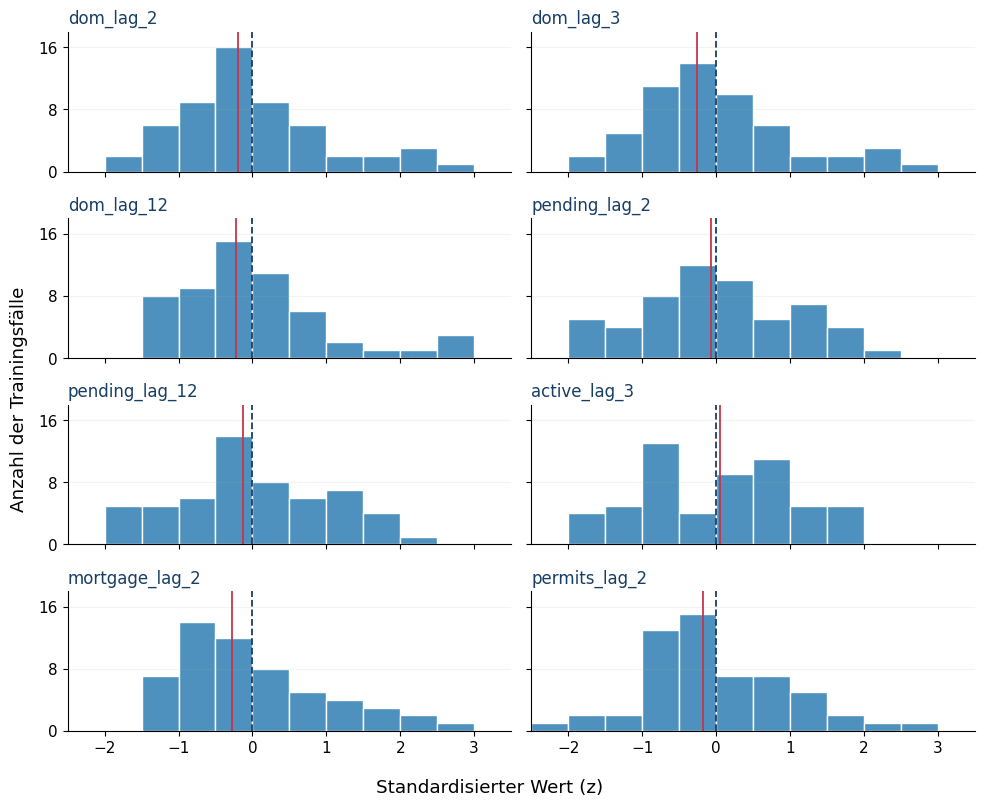

In [ ]:
fig, axes = plt.subplots(4, 2, figsize=(10, 8.1), sharex=True, sharey=True)
for ax, feature in zip(axes.flat, lag_columns):
    ax.hist(scaled_data[feature], bins=np.arange(-2.5, 3.51, 0.5), color=plot_light_blue, edgecolor="white")
    ax.axvline(0, color=plot_blue, linestyle="--", linewidth=1.3)
    ax.axvline(scaled_data[feature].median(), color=plot_red, linewidth=1.3)
    ax.set_title(feature, loc="left", fontsize=12, color=plot_blue)
    ax.set_xlim(-2.5, 3.5); ax.set_ylim(0, 18); ax.set_yticks([0, 8, 16])
    ax.grid(axis="y", alpha=0.15)
    ax.spines[["top", "right"]].set_visible(False)
fig.supxlabel("Standardisierter Wert (z)")
fig.supylabel("Anzahl der Trainingsfälle")
fig.tight_layout(pad=1.0)
show_figure(fig, "01_histogramme.png")

distribution_rows = []
for feature in lag_columns:
    values = raw_data[feature]
    first_quartile, third_quartile = values.quantile([0.25, 0.75])
    interquartile_range = third_quartile - first_quartile
    flagged = (values < first_quartile - 1.5 * interquartile_range) | (values > third_quartile + 1.5 * interquartile_range)
    distribution_rows.append({"Feature": feature, "Anzahl": values.count(), "Schiefe": values.skew(), "IQR-Markierungen": int(flagged.sum())})
distribution_summary = pd.DataFrame(distribution_rows)
distribution_summary.to_csv(output_dir / "verteilungen.csv", index=False)

## 3. Zeitliche Entwicklung untersuchen

Die Zeitreihen zeigen, wann hohe und niedrige Feature-Werte auftreten. Die Zeitachse bezeichnet den Prognoseursprung. Ein Lag-2-Wert stammt jeweils aus zwei Monaten zuvor. Derselbe ursprüngliche Messwert kann daher in verschiedenen Lag-Spalten zu unterschiedlichen Zeitpunkten erscheinen. Das sind keine unabhängigen Ereignisse.


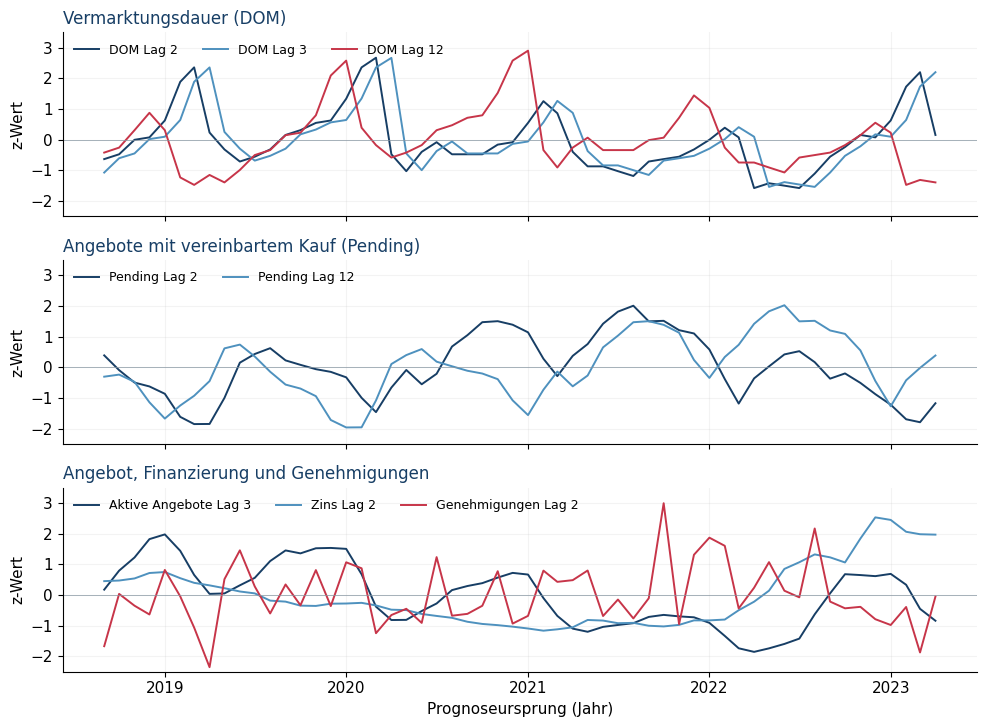

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(10, 7.4), sharex=True)
feature_groups = [lag_columns[:3], lag_columns[3:5], lag_columns[5:8]]
legend_groups = [["DOM Lag 2", "DOM Lag 3", "DOM Lag 12"], ["Pending Lag 2", "Pending Lag 12"], ["Aktive Angebote Lag 3", "Zins Lag 2", "Genehmigungen Lag 2"]]
plot_titles = ["Vermarktungsdauer (DOM)", "Angebote mit vereinbartem Kauf (Pending)", "Angebot, Finanzierung und Genehmigungen"]
for ax, features, labels, title in zip(axes, feature_groups, legend_groups, plot_titles):
    for feature, label, color in zip(features, labels, [plot_blue, plot_light_blue, plot_red]):
        ax.plot(scaled_data.origin_month, scaled_data[feature], label=label, color=color, linewidth=1.4)
    ax.set_title(title, loc="left", fontsize=12, color=plot_blue)
    ax.set_ylim(-2.5, 3.5); ax.set_ylabel("z-Wert")
    ax.grid(alpha=0.15); ax.axhline(0, color="#8796A2", linewidth=0.5)
    ax.legend(fontsize=9, ncol=3, loc="upper left", frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
axes[-1].xaxis.set_major_locator(mdates.YearLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[-1].set_xlabel("Prognoseursprung (Jahr)")
fig.tight_layout()
show_figure(fig, "02_zeitverlaeufe.png")

## 4. Zusammenhänge zwischen Features prüfen

Die Korrelationsmatrix zeigt, welche Merkmale gemeinsam steigen oder sich gegenläufig bewegen. Rot kennzeichnet positive und Blau negative Zusammenhänge. Starke Beziehungen können auf ähnliche Informationen hinweisen. Sie belegen weder einen kausalen Einfluss noch eine gute Vorhersage. Ergänzend wird mit Spearman geprüft, ob ausgewählte Beziehungen auch anhand der Rangfolge der Werte bestehen.


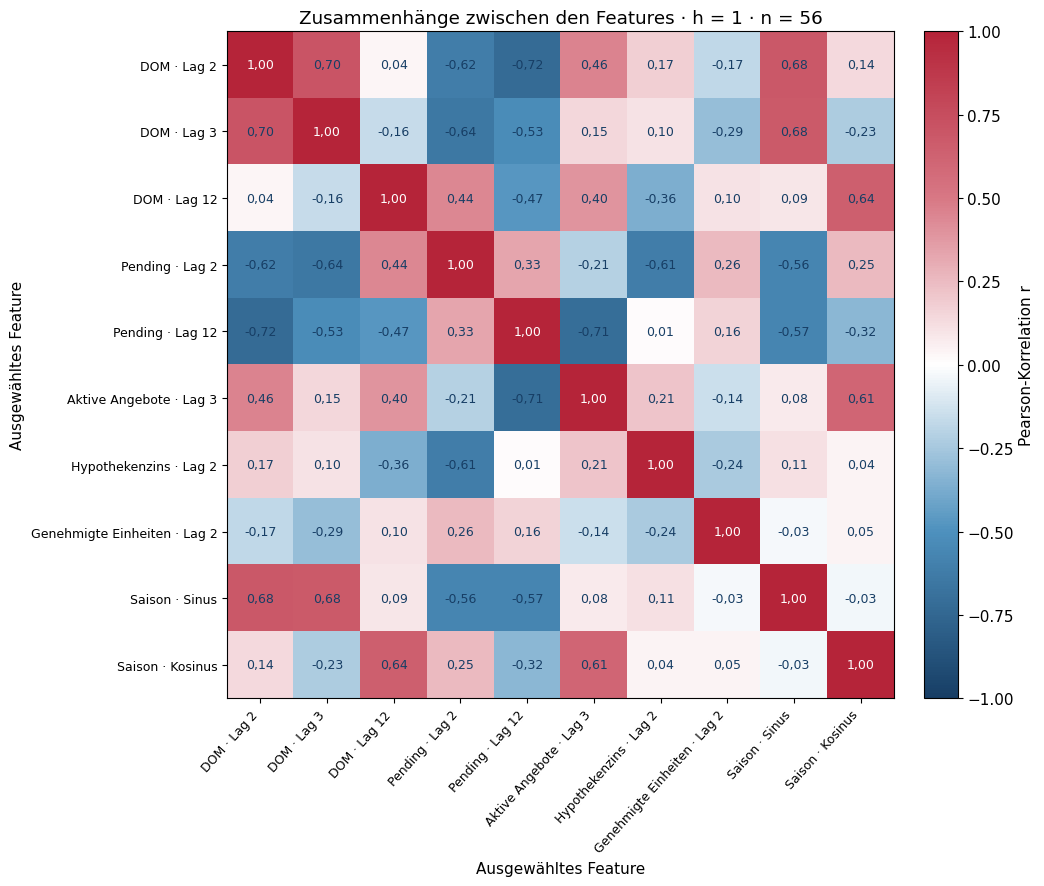

In [ ]:
pearson_matrix = scaled_data[feature_columns].corr()
spearman_matrix = scaled_data[feature_columns].corr(method="spearman")
np.testing.assert_allclose(pearson_matrix, raw_data[feature_columns].corr(), atol=1e-12)
feature_labels = ["DOM · Lag 2", "DOM · Lag 3", "DOM · Lag 12", "Pending · Lag 2", "Pending · Lag 12", "Aktive Angebote · Lag 3", "Hypothekenzins · Lag 2", "Genehmigte Einheiten · Lag 2", "Saison · Sinus", "Saison · Kosinus"]
fig, ax = plt.subplots(figsize=(11, 9))
heatmap = ax.imshow(pearson_matrix, cmap=plot_cmap, vmin=-1, vmax=1)
ax.set_xticks(range(10), feature_labels, rotation=48, ha="right", fontsize=9)
ax.set_yticks(range(10), feature_labels, fontsize=9)
for row_index in range(10):
    for column_index in range(10):
        value = pearson_matrix.iloc[row_index, column_index]
        ax.text(column_index, row_index, f"{value:.2f}".replace(".", ","), ha="center", va="center", fontsize=9, color="white" if abs(value) > 0.75 else plot_blue)
fig.colorbar(heatmap, ax=ax, fraction=0.045, pad=0.035).set_label("Pearson-Korrelation r")
ax.set(xlabel="Ausgewähltes Feature", ylabel="Ausgewähltes Feature", title="Zusammenhänge zwischen den Features · h = 1 · n = 56")
fig.tight_layout()
show_figure(fig, "03_korrelationsmatrix.png")
pearson_matrix.to_csv(output_dir / "pearson_korrelation.csv")
spearman_matrix.to_csv(output_dir / "spearman_korrelation.csv")

## 5. Beziehungen zu zukünftigen Zielwerten untersuchen

Die Streudiagramme vergleichen frühere Merkmale mit späteren DOM- und Pending-Werten. Bei Lag 2 und einem Prognosehorizont von einem Monat liegen drei Monate zwischen den Messwerten. Ergänzend werden verschiedene Horizonte verglichen. Eine zweite Prüfung verwendet dieselben Prognoseursprünge, damit Unterschiede der Stichproben erkennbar werden. Es wird noch kein Vorhersagemodell trainiert.


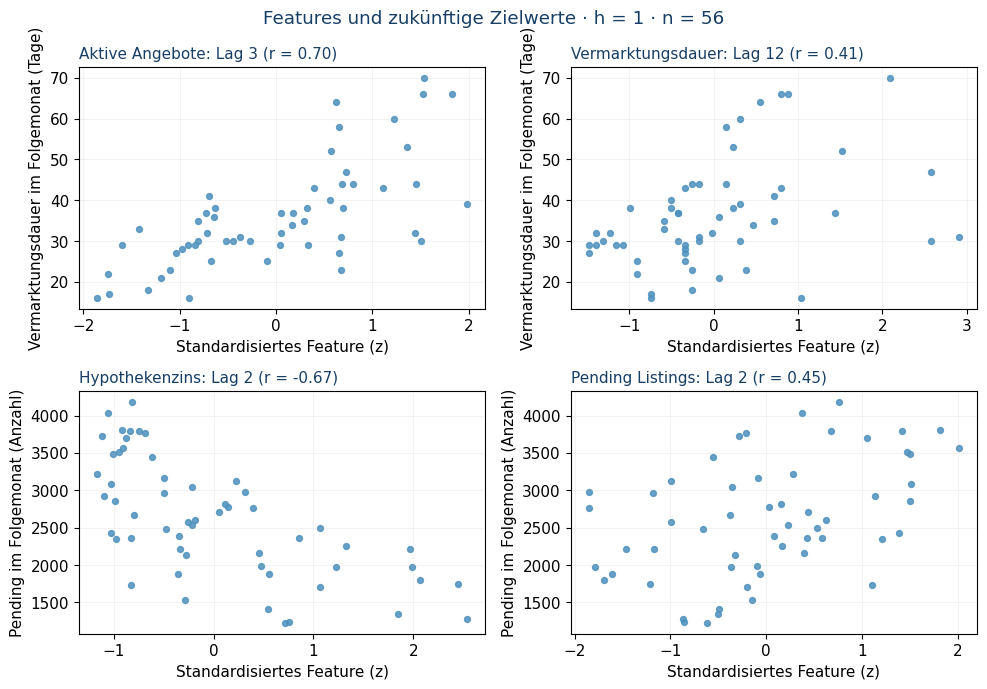

In [ ]:
scatter_pairs = [
    ("active_lag_3", "target_dom", "Aktive Angebote: Lag 3"),
    ("dom_lag_12", "target_dom", "Vermarktungsdauer: Lag 12"),
    ("mortgage_lag_2", "target_pending", "Hypothekenzins: Lag 2"),
    ("pending_lag_2", "target_pending", "Pending Listings: Lag 2"),
]
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, (feature, target, title) in zip(axes.flat, scatter_pairs):
    correlation_value = scaled_data[feature].corr(scaled_data[target])
    ax.scatter(scaled_data[feature], scaled_data[target], color=plot_light_blue, s=18, alpha=0.85)
    ax.set_title(f"{title} (r = {correlation_value:.2f})", loc="left", color=plot_blue, fontsize=11)
    ax.set_xlabel("Standardisiertes Feature (z)")
    ax.set_ylabel("Vermarktungsdauer im Folgemonat (Tage)" if target == "target_dom" else "Pending im Folgemonat (Anzahl)")
    ax.grid(alpha=0.15)
fig.suptitle("Features und zukünftige Zielwerte · h = 1 · n = 56", color=plot_blue)
fig.tight_layout()
show_figure(fig, "04_zukuenftige_zielwerte.png")

correlation_rows = []
for horizon, frame in scaled_tables.items():
    for feature in feature_columns:
        for target in ["target_dom", "target_pending"]:
            correlation_rows.append({"horizon": horizon, "feature": feature, "target": target, "n": len(frame), "pearson_r": frame[feature].corr(frame[target])})
pd.DataFrame(correlation_rows).to_csv(output_dir / "feature_target_korrelationen.csv", index=False)
selected_horizons = [1, 3, 6, 12]
def horizon_summary(frames):
    return pd.DataFrame([{"Horizont": horizon, "Anzahl": len(frames[horizon]),
        "Active Lag 3 → DOM": frames[horizon].active_lag_3.corr(frames[horizon].target_dom),
        "Mortgage Lag 2 → Pending": frames[horizon].mortgage_lag_2.corr(frames[horizon].target_pending)}
        for horizon in selected_horizons])
horizon_summary(scaled_tables).to_csv(output_dir / "horizontvergleich.csv", index=False)
common_origins = set.intersection(*(set(scaled_tables[horizon].origin_month) for horizon in selected_horizons))
common_tables = {horizon: scaled_tables[horizon].loc[scaled_tables[horizon].origin_month.isin(common_origins)] for horizon in selected_horizons}
assert len(common_origins) == 45
horizon_summary(common_tables).to_csv(output_dir / "horizontvergleich_gemeinsame_urspruenge.csv", index=False)

## 6. Saisonmuster mit Boxplots und Heatmaps zeigen

Die Monatsboxplots zeigen typische Werte und ihre Streuung je Kalendermonat. Sie verwenden die Zielmonate Oktober 2018 bis Mai 2023. Die anschließenden Heatmaps zeigen für die vollständigen Jahre 2019 bis 2022 die prozentuale Abweichung vom jeweiligen Jahresdurchschnitt. So lässt sich erkennen, ob die Muster in mehreren Jahren auftreten. Der Jahresdurchschnitt dient nur der rückblickenden Darstellung und wird nicht als Prognosemerkmal verwendet.


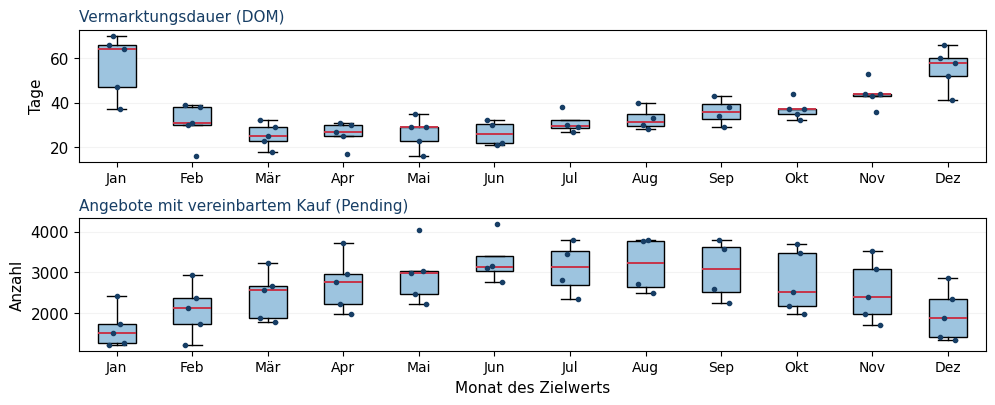

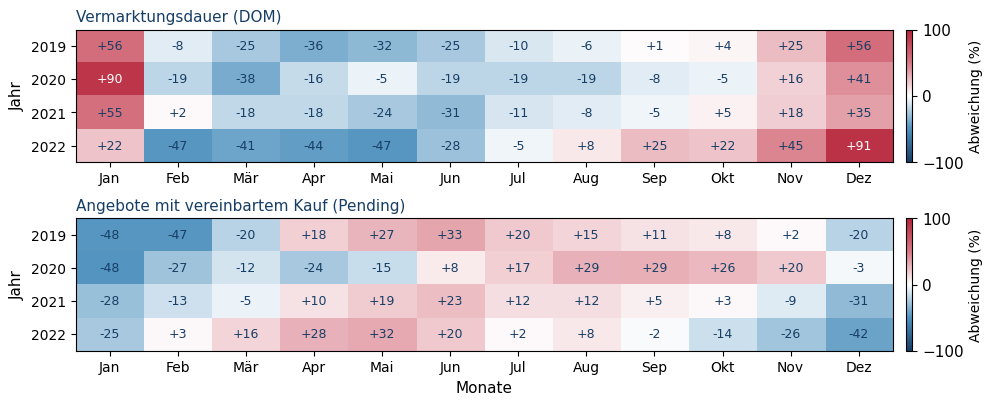

In [ ]:
seasonal_data = raw_data[["target_month", "target_dom", "target_pending"]].copy()
seasonal_data["month"] = seasonal_data.target_month.dt.month
seasonal_data["year"] = seasonal_data.target_month.dt.year
month_labels = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]
target_titles = ["Vermarktungsdauer (DOM)", "Angebote mit vereinbartem Kauf (Pending)"]
fig, axes = plt.subplots(2, 1, figsize=(10, 4.1))
for ax, target, title, unit in zip(axes, ["target_dom", "target_pending"], target_titles, ["Tage", "Anzahl"]):
    month_values = [seasonal_data.loc[seasonal_data.month == month, target].to_numpy() for month in range(1, 13)]
    box = ax.boxplot(month_values, patch_artist=True, widths=0.5, showfliers=False, medianprops={"color": plot_red, "linewidth": 1.4})
    for patch in box["boxes"]:
        patch.set_facecolor("#9DC4DF")
    for month, values in enumerate(month_values, start=1):
        ax.scatter(month + np.linspace(-0.1, 0.1, len(values)), values, s=9, color=plot_blue, zorder=3)
    ax.set_title(title, loc="left", fontsize=11, color=plot_blue)
    ax.set_ylabel(unit); ax.set_xticks(range(1, 13), month_labels, fontsize=10)
    ax.grid(axis="y", alpha=0.15)
axes[-1].set_xlabel("Monat des Zielwerts")
fig.tight_layout(pad=0.8)
show_figure(fig, "05_monatsboxplots.png")

full_years = seasonal_data.groupby("year").month.nunique()
full_years = full_years[full_years == 12].index.tolist()
assert full_years == [2019, 2020, 2021, 2022]
annual_deviations = {}
fig, axes = plt.subplots(2, 1, figsize=(10, 4.1))
for ax, target, title in zip(axes, ["target_dom", "target_pending"], target_titles):
    year_month_values = seasonal_data.loc[seasonal_data.year.isin(full_years)].pivot(index="year", columns="month", values=target)
    deviations = 100 * (year_month_values.div(year_month_values.mean(axis=1), axis=0) - 1)
    annual_deviations[target] = deviations
    heatmap = ax.imshow(deviations, cmap=plot_cmap, vmin=-100, vmax=100, aspect="auto")
    for row_index in range(len(deviations)):
        for column_index in range(12):
            value = deviations.iloc[row_index, column_index]
            ax.text(column_index, row_index, f"{value:+.0f}", ha="center", va="center", fontsize=9, color="white" if abs(value) > 70 else plot_blue)
    ax.set_yticks(range(len(deviations)), deviations.index, fontsize=10)
    ax.set_xticks(range(12), month_labels, fontsize=10)
    ax.set_title(title, loc="left", fontsize=11, color=plot_blue)
    ax.set_ylabel("Jahr")
    fig.colorbar(heatmap, ax=ax, pad=0.015, fraction=0.025, ticks=[-100, 0, 100]).set_label("Abweichung (%)", fontsize=10)
    deviations.to_csv(output_dir / f"saisonabweichung_{target}.csv")
axes[-1].set_xlabel("Monate")
fig.tight_layout(pad=0.8)
show_figure(fig, "06_saison_heatmaps.png")


## 7. Ergänzende Korrelation berechnen

Abschließend wird die Korrelation zwischen den gleichzeitigen DOM- und Pending-Zielwerten berechnet. Die Interpretation und die Zusammenfassung der Hypothesen erfolgen in der Dokumentation.


In [2]:
concurrent_correlation = raw_data.target_dom.corr(raw_data.target_pending)
print(f"Korrelation gleichzeitiger DOM- und Pending-Zielwerte: r = {concurrent_correlation:.2f}")


Korrelation gleichzeitiger DOM- und Pending-Zielwerte: r = -0.58
